# Analisis RFM Pelanggan Olist

Notebook ini menghitung segmentasi **RFM** (Recency, Frequency, Monetary) pada dataset
Olist Brazilian E-Commerce, lalu menafsirkan hasilnya. Angka di sini sama dengan yang
dipakai dashboard CRM, karena keduanya memakai modul `src` yang sama.

Jalankan dari akar proyek `W11`:

```bash
jupyter notebook rfm_analisis.ipynb
```

- **Recency**: jumlah hari sejak transaksi terakhir. Tanggal analisis tetap
  4 September 2018 agar nilai recency dapat dibandingkan.
- **Frequency**: jumlah pesanan pelanggan.
- **Monetary**: total nilai belanja pelanggan dalam Real Brazil (R$).

## 1. Menyiapkan data

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_orders, valid_orders, snapshot_date
from src.analytics import build_customers, segment_summary, rfm_grid, loyalty_kpis
from src.formatting import money, number, percent

orders = valid_orders(load_orders())
snapshot = snapshot_date(load_orders())
customers = build_customers(orders, snapshot)

print(f"Tanggal analisis : {snapshot.date()}")
print(f"Pesanan sah      : {len(orders):,} pesanan")
print(f"Pelanggan unik   : {customers['customer_uid'].nunique():,}")

Tanggal analisis : 2018-09-04
Pesanan sah      : 98,207 pesanan
Pelanggan unik   : 94,990


## 2. Cara skor RFM dihitung

Recency dan Monetary dibagi menjadi skor 1 sampai 5 memakai **kuantil** (peringkat
persentil), sehingga tiap tingkat berisi porsi pelanggan yang kurang lebih sama.
Frequency tidak bisa memakai kuantil, karena sekitar 97% pelanggan hanya membeli satu
kali; kuantil akan menaruh hampir semua orang di satu tingkat. Karena itu Frequency
memakai pemetaan eksplisit:

| Jumlah pesanan | Skor F |
|---|---|
| 1 | F1 |
| 2 | F3 |
| 3 | F4 |
| 4 atau lebih | F5 |

Kombinasi ketiga skor dipetakan ke sepuluh segmen: Juara, Loyal, Berpotensi Loyal,
Pelanggan Baru, Menjanjikan, Perlu Perhatian, Tidak Boleh Hilang, Berisiko, Tidur, dan
Hilang.

## 3. Contoh hasil per pelanggan

In [2]:
cols = ["customer_uid", "recency", "n_orders", "monetary", "r_score", "f_score", "m_score", "segment"]
head = customers[cols].head(10).copy()
head["customer_uid"] = head["customer_uid"].str[:10].str.upper()
head["monetary"] = head["monetary"].map(money)
print(head.rename(columns={
    "customer_uid": "id", "recency": "recency_hari", "n_orders": "pesanan",
    "monetary": "belanja", "segment": "segmen",
}).to_string(index=False))

        id  recency_hari  pesanan belanja  r_score  f_score  m_score         segmen
0000366F3B           116        1  R$ 142        4        1        4 Pelanggan Baru
0000B849F7           119        1   R$ 27        4        1        1 Pelanggan Baru
0000F46A39           542        1   R$ 86        1        1        2         Hilang
0000F6CCB0           326        1   R$ 44        2        1        1         Hilang
0004AAC84E           293        1  R$ 197        2        1        4       Berisiko
0004BD2A26           151        1  R$ 167        4        1        4 Pelanggan Baru
00050AB131           136        1   R$ 35        4        1        1 Pelanggan Baru
00053A61A9           187        1  R$ 419        3        1        5    Menjanjikan
0005E18622           548        1  R$ 150        1        1        4       Berisiko
0005EF4CD2           175        1  R$ 130        4        1        3 Pelanggan Baru


## 4. Sebaran skor

Jumlah pelanggan pada tiap tingkat skor. Recency dan Monetary tersebar merata karena
memakai kuantil, sedangkan Frequency menumpuk di skor rendah karena rendahnya
pembelian ulang.

In [3]:
dist = pd.DataFrame({
    "skor": [1, 2, 3, 4, 5],
    "Recency":   [(customers["r_score"] == s).sum() for s in range(1, 6)],
    "Frequency": [(customers["f_score"] == s).sum() for s in range(1, 6)],
    "Monetary":  [(customers["m_score"] == s).sum() for s in range(1, 6)],
})
print(dist.to_string(index=False))

 skor  Recency  Frequency  Monetary
    1    18969      92102     19001
    2    18929          0     18998
    3    19007       2652     18994
    4    19093        188     18997
    5    18992         48     19000


## 5. Matriks Recency x Frequency

Warna dan angka menunjukkan jumlah pelanggan pada setiap kombinasi tingkat Recency
(baris) dan jumlah pesanan (kolom). Sel kanan atas berisi pelanggan paling aktif.

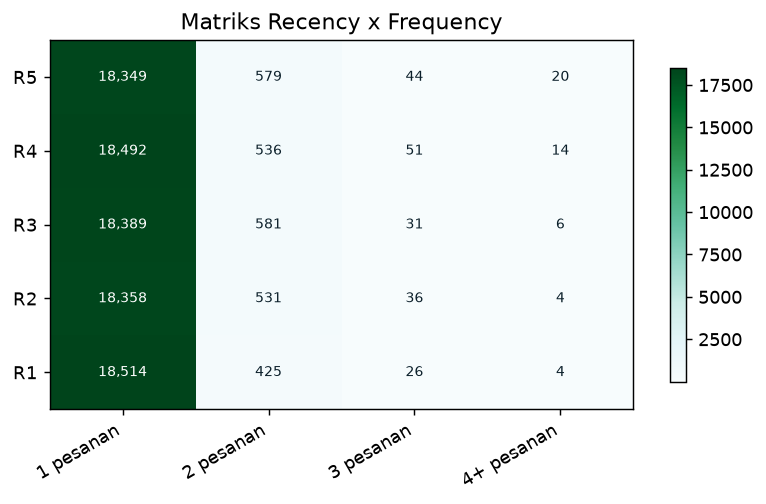

In [4]:
grid = rfm_grid(customers, "pelanggan")
fig, ax = plt.subplots(figsize=(6.2, 4))
image = ax.imshow(grid.values, cmap="BuGn", aspect="auto")
ax.set_xticks(range(len(grid.columns)), grid.columns, rotation=30, ha="right")
ax.set_yticks(range(len(grid.index)), [f"R{int(i)}" for i in grid.index])
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        value = grid.values[i, j]
        if value > 0:
            ax.text(j, i, f"{value:,.0f}", ha="center", va="center", fontsize=8,
                    color="white" if value / grid.values.max() > 0.55 else "#0B1F2A")
ax.set_title("Matriks Recency x Frequency")
plt.colorbar(image, ax=ax, shrink=0.85)
plt.tight_layout()

## 6. Ringkasan per segmen

In [5]:
seg = segment_summary(customers)[
    ["segment", "pelanggan", "porsi_pelanggan", "pendapatan", "porsi_pendapatan", "nilai", "risiko"]
].copy()
seg["pelanggan"] = seg["pelanggan"].map(lambda v: number(int(v)))
seg["porsi_pelanggan"] = seg["porsi_pelanggan"].map(percent)
seg["pendapatan"] = seg["pendapatan"].map(money)
seg["porsi_pendapatan"] = seg["porsi_pendapatan"].map(percent)
seg["nilai"] = seg["nilai"].map(money)
seg["risiko"] = seg["risiko"].map(lambda v: number(v, 1))
print(seg.rename(columns={"segment": "segmen", "nilai": "nilai_median", "risiko": "skor_risiko"}).to_string(index=False))

            segmen pelanggan porsi_pelanggan   pendapatan porsi_pendapatan nilai_median skor_risiko
    Pelanggan Baru    36.841           38,8% R$ 6.070.331            38,6%       R$ 108        33,8
          Berisiko    13.953           14,7% R$ 4.316.099            27,4%       R$ 212        71,1
       Menjanjikan    18.389           19,4% R$ 2.793.750            17,8%       R$ 105        54,6
            Hilang    15.663           16,5%   R$ 874.488             5,6%        R$ 57        70,6
             Tidur     7.342            7,7%   R$ 800.102             5,1%       R$ 108        71,1
  Berpotensi Loyal     1.115            1,2%   R$ 329.482             2,1%       R$ 225        25,6
Tidak Boleh Hilang       940            1,0%   R$ 295.330             1,9%       R$ 227        62,4
   Perlu Perhatian       581            0,6%   R$ 170.998             1,1%       R$ 222        46,5
             Juara       124            0,1%    R$ 69.535             0,4%       R$ 434        20,6


## 7. Pendapatan menurut segmen

Diurutkan menurut pendapatan yang dibawa. Segmen Pelanggan Baru dan Berisiko
mendominasi pendapatan, tanda basis pelanggan yang masih muda dan mudah menguap.

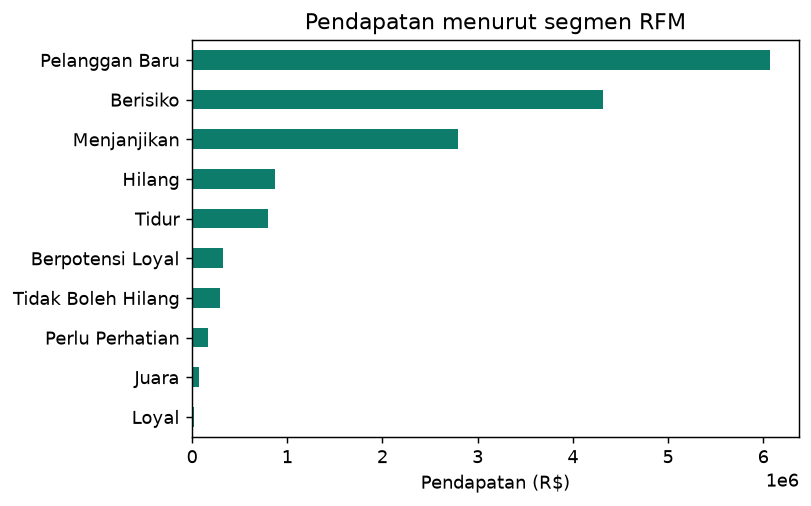

In [6]:
segments = segment_summary(customers).sort_values("pendapatan")
ax = segments.set_index("segment")["pendapatan"].plot.barh(
    figsize=(6.4, 4), color="#0E7C6B", title="Pendapatan menurut segmen RFM"
)
ax.set_xlabel("Pendapatan (R$)")
ax.set_ylabel("")
plt.tight_layout()

## 8. Sepuluh pelanggan dengan nilai belanja terbesar

In [7]:
top = customers.sort_values("monetary", ascending=False).head(10)
top_view = pd.DataFrame({
    "id": top["customer_uid"].str[:10].str.upper(),
    "kota": top["city"],
    "negara_bagian": top["state"],
    "pesanan": top["n_orders"].astype(int),
    "belanja": top["monetary"].map(money),
    "nilai_pesanan": top["avg_order_value"].map(money),
    "segmen": top["segment"].astype(str),
})
print(top_view.to_string(index=False))

        id           kota negara_bagian  pesanan   belanja nilai_pesanan             segmen
0A0A92112B Rio De Janeiro            RJ        1 R$ 13.664     R$ 13.664           Berisiko
DA122DF9EE       Araruama            RJ        2  R$ 7.572      R$ 3.786 Tidak Boleh Hilang
763C8B1C9C     Vila Velha            ES        1  R$ 7.275      R$ 7.275     Pelanggan Baru
DC4802A71E   Campo Grande            MS        1  R$ 6.929      R$ 6.929           Berisiko
459BEF4868        Vitoria            ES        1  R$ 6.922      R$ 6.922     Pelanggan Baru
FF4159B92C        Marilia            SP        1  R$ 6.727      R$ 6.727           Berisiko
4007669DEC    Divinopolis            MG        1  R$ 6.082      R$ 6.082           Berisiko
EEBB5DDA14           Maua            SP        1  R$ 4.764      R$ 4.764           Berisiko
48E1AC109D    Joao Pessoa            PB        1  R$ 4.682      R$ 4.682     Pelanggan Baru
C8460E4251   Porto Alegre            RS        4  R$ 4.656      R$ 1.164        

## 9. Metrik loyalitas

In [8]:
lk = loyalty_kpis(orders, customers, snapshot)
print(f"Repeat rate (lebih dari satu pesanan) : {percent(lk['repeat_rate'])}")
print(f"Pembelian ulang <=90 hari             : {percent(lk['repeat_90d'])} dari {number(lk['repeat_90d_n'])} pelanggan teramati")
print(f"Pesanan rata-rata per pelanggan       : {number(lk['avg_orders'], 2)}")
print(f"Jeda median antar transaksi           : {number(lk['median_interval'])} hari")
print(f"Pelanggan berulang                    : {number(lk['loyal_customers'])}")

Repeat rate (lebih dari satu pesanan) : 3,0%
Pembelian ulang <=90 hari             : 1,3% dari 77.742 pelanggan teramati
Pesanan rata-rata per pelanggan       : 1,03
Jeda median antar transaksi           : 41 hari
Pelanggan berulang                    : 2.888


## 10. Kesimpulan

1. Belanja pelanggan sangat miring. Median belanja hanya R$ 108, tetapi
   sebagian kecil pelanggan bernilai sangat tinggi. 20% pelanggan teratas menyumbang
   sekitar 53,6% pendapatan.
2. Repeat rate hanya 3,0%. Segmen Juara (124 pelanggan)
   dan Loyal (42 pelanggan) otomatis kecil. Ini karakter pasar, bukan
   kesalahan segmentasi.
3. Karena pembelian ulang jarang, Frequency berupa pemetaan eksplisit lebih jujur
   daripada kuantil.
4. Prioritas tindakan: selamatkan pelanggan bernilai tinggi yang mulai hilang (segmen
   Tidak Boleh Hilang dan Berisiko), lalu dorong pembelian kedua pada pelanggan baru.

**Keterbatasan.** Data berakhir pada 2018-09-04 sehingga churn tidak dapat diukur
langsung. Skor RFM bersifat deskriptif untuk memprioritaskan tindakan, bukan model
prediktif.